# Crypto Mean-Reversion Pairs Strategy
### Research Objective

This notebook investigates whether short-horizon mean reversion in cryptocurrency markets can be systematically exploited through a long-short relative-value pairs trading strategy designed to reduce directional market exposure.

The central hypothesis is that some crypto pairs exhibit sufficiently stable long-run relationships that temporary deviations from their historical equilibrium can subsequently reverse. The strategy attempts to identify such pairs, quantify the deviation using a rolling Z-score, and take positions when the deviation is sufficiently large.

The analysis is designed as a quantitative research exercise and particular attention is therefore paid to out-of-sample evaluation, transaction costs, parameter selection, and the stability of the underlying relationships.

In [1]:
import time
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint
from scipy.stats import ttest_rel

pd.set_option("display.width", 140)

### Data and Universe

The initial universe consists of 40 cryptocurrency assets. Historical OHLCV data are collected through the Coinbase exchange using CCXT.
However, a data availability check is done later, revealing that 2 of the coins do not have enough data until the present to match the other 38 coins, hence they are dropped from the list.

The analysis uses closing prices and trading volume. Although the raw data are collected at an hourly frequency, the strategy is evaluated across several candidate sampling frequencies during parameter selection.

At the initial data collection stage, 35 of the 38 assets have the required Coinbase USD market available. This produces
35C2 = 595 candidate pairs for the initial screening process.

The common aligned hourly sample spans approximately August 28, 2021 through August 28, 2026. Assets are aligned using timestamps shared across the available universe.

In [28]:
UNIVERSE = ["BTC", "ETH", "SOL", "BNB", "XRP", "DOGE", "ADA", "LINK", "AVAX", "DOT", 
            "LTC", "ATOM", "AAVE", "UNI", "ARB", "OP", "SUI", "NEAR", "ALGO", "FIL", 
            "MATIC", "TRX", "BCH", "ETC", "XLM", "ICP", "APT", "SEI", "INJ", "RENDER", 
            "FET", "TIA", "HBAR", "VET", "THETA", "SAND", "MANA", "GRT"]
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [29]:
exchange = ccxt.coinbase({"enableRateLimit": True, "timeout": 30000})
markets = exchange.load_markets()

symbols = [f"{coin}/USD" for coin in UNIVERSE if f"{coin}/USD" in markets]
pairs = list(combinations(symbols, 2))
print(f"{len(symbols)} coins available, {len(pairs)} candidate pairs")

35 coins available, 595 candidate pairs


In [30]:
# ----------------------------------------------
# Format timestamp column; rename df columns function
# ----------------------------------------------
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close", "volume"]].copy()
    df = df.rename(columns={"close": symbol, "volume": f"{symbol}_volume"})
    return df

In [31]:
# ----------------------------------------------
# Fetch market data function
# ----------------------------------------------
def fetch_ohlcv_history(exchange, symbol, timeframe, since_ms, limit=300, max_retries=5):
    all_rows = []
    since = since_ms
    now_ms = exchange.milliseconds()

    while since < now_ms:
        batch = None
        for attempt in range(max_retries):
            try:
                batch = exchange.fetch_ohlcv(symbol, timeframe=timeframe, since=since, limit=limit)
                break
            except (ccxt.RequestTimeout, ccxt.NetworkError) as e:
                if attempt == max_retries - 1:
                    raise
                time.sleep(2 ** attempt)

        if not batch:
            break

        all_rows.extend(batch)
        since = batch[-1][0] + 1

    return all_rows

### Data Preparation

The raw hourly observations are converted into a common timestamp index and merged across assets. The analysis retains the original 1-hour dataset so that alternative strategy sampling frequencies can be evaluated later.

For a selected timeframe (h), prices are resampled using the last observed price in each interval, while trading volume is aggregated across the interval.

This produces a consistent panel of synchronized prices and volumes for pair construction and backtesting.

The data-availability check was performed in this section. This is important because an apparently attractive backtest can otherwise be affected by assets entering or leaving the sample at different dates.

In [32]:
# ----------------------------------------------
# Fetch price data for each coin in universe
# ----------------------------------------------

YEARS_OF_HISTORY = 5 
TIMEFRAME = "1h"

since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)
HISTORY_SINCE = exchange.parse8601(since_dt.strftime("%Y-%m-%dT%H:%M:%SZ"))

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_9121/1440727707.py:8: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)


In [34]:
asset_ranges = {}

prices = None
for coin in UNIVERSE:
    symbol = f"{coin}/USD"
    if symbol not in markets:
        continue
    data = fetch_ohlcv_history(exchange, symbol, timeframe=TIMEFRAME, since_ms=HISTORY_SINCE)
    if not data:
        continue
    df = to_df(data, coin)
    asset_ranges[coin] = {"start": df["timestamp"].min(), "end": df["timestamp"].max(), "n_bars": len(df)}

    prices = df if prices is None else prices.merge(df, on="timestamp", how="inner")

prices = prices.sort_values("timestamp").reset_index(drop=True)

print(f"{len(prices)} aligned hourly bars, {prices['timestamp'].min()} -> {prices['timestamp'].max()}")

43627 aligned hourly bars, 2021-08-28 18:00:00 -> 2026-08-28 17:00:00


In [35]:
asset_ranges_df = (pd.DataFrame(asset_ranges).T.sort_values("end"))
asset_ranges_df

,start,end,n_bars
MANA,2021-08-28 18:00:00,2026-08-28 17:00:00,43710
BTC,2021-08-28 18:00:00,2026-08-28 18:00:00,43812
FET,2021-08-28 18:00:00,2026-08-28 18:00:00,43809
ICP,2021-08-28 18:00:00,2026-08-28 18:00:00,43799
XLM,2021-08-28 18:00:00,2026-08-28 18:00:00,43810
ETC,2021-08-28 18:00:00,2026-08-28 18:00:00,43804
BCH,2021-08-28 18:00:00,2026-08-28 18:00:00,43811
FIL,2021-08-28 18:00:00,2026-08-28 18:00:00,43809
ALGO,2021-08-28 18:00:00,2026-08-28 18:00:00,43809
UNI,2021-08-28 18:00:00,2026-08-28 18:00:00,43810


In [36]:
final_date = asset_ranges_df["end"].max()
problem_assets = asset_ranges_df[asset_ranges_df["end"] < final_date].sort_values("end")
problem_assets

,start,end,n_bars
MANA,2021-08-28 18:00:00,2026-08-28 17:00:00,43710


In [37]:
# Keep the original 1h data so we can compare 4h / 8h / 12h later.
prices_1h = prices.copy()

# Main run stays at 4h, just like the original notebook.
prices = prices_1h.set_index("timestamp").resample("4h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

In [38]:
# What coins had available data out of the original universe
available_assets = [c for c in UNIVERSE if c in prices.columns]
symbols = [f"{c}/USD" for c in available_assets]
pairs = list(combinations(symbols, 2))

### Train/Test Split

To separate model development from final evaluation, the data are divided chronologically into a 70% training period and 30% holdout period. Because the final evaluation is conducted on complete calendar quarters, the quarterly walk-forward test begins on April 1, 2025, after the training period ends in Q1 2025.

The resulting split is:

Training: August 28, 2021 – February 26, 2025
Test: February 26, 2025 – August 28, 2026

No information from the future test period is used when estimating the initial training-period pair relationships or selecting the strategy parameters.

The test period is subsequently evaluated using a quarterly walk-forward procedure, so pair selection and hedge-ratio estimation are updated using only information available before each quarter.

The objective is not simply to find the best parameters over the entire historical sample, but to determine whether the research process continues to work when applied sequentially to unseen data.

In [39]:
# ----------------------------------------------
# Split price data into train and test (70/30)
# ----------------------------------------------
TRAIN_FRAC = 0.7

split_idx = int(len(prices) * TRAIN_FRAC)
train_prices = prices.iloc[:split_idx].reset_index(drop=True)
test_prices = prices.iloc[split_idx:].reset_index(drop=True)

print(f"Train: {train_prices['timestamp'].min()} -> {train_prices['timestamp'].max()}  ({len(train_prices)} bars)")
print(f"Test:  {test_prices['timestamp'].min()} -> {test_prices['timestamp'].max()}  ({len(test_prices)} bars)")

Train: 2021-08-28 16:00:00 -> 2025-02-26 08:00:00  (7667 bars)
Test:  2025-02-26 12:00:00 -> 2026-08-28 16:00:00  (3286 bars)


### Pair Construction and Hedge Ratio

For each candidate pair, the strategy models the relationship between the logarithms of the two asset prices.

For assets (A) and (B), 
$$
[
\log(P_A)=\alpha+\beta\log(P_B)+\varepsilon.
]
$$
The residual
$$
\log(P_{A,t})

\left(\alpha+\beta\log(P_{B,t})\right)
]$$
is interpreted as the pair's spread.

The estimated coefficient beta serves as the hedge ratio. If the relationship is stable, deviations of the spread away from its historical equilibrium may be expected to partially reverse.

During walk-forward evaluation, alpha and beta are estimated using only the historical window available before each evaluation quarter. When the model is applied to a new test period, the spread is constructed using those previously estimated coefficients rather than refitting them using future observations.

In [40]:
# ----------------------------------------------
# Align timestamp for price data of 2 assets
# ----------------------------------------------
def align_pair_prices(prices, asset_a, asset_b):
    cols = ["timestamp", asset_a, asset_b]
    vol_cols = [f"{asset_a}_volume", f"{asset_b}_volume"]
    needed = cols + [c for c in vol_cols if c in prices.columns]
    out = prices[needed].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [41]:
# ----------------------------------------------
# Regress log prices of assets to get alpha, beta, corr, and EG function
# ----------------------------------------------
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Fit the hedge ratio via OLS (used ONLY on the train set) and run the
    Engle-Granger cointegration test on the two log-price series.
    Two nonstationary series can produce a highly significant OLS slope
    just because both trend -- that p-value is NOT a cointegration test,
    so we report the Engle-Granger p-value instead.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]
    model = sm.OLS(y, X).fit()
    
    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]
    out["spread"] = model.resid

    eg_stat, eg_pvalue, eg_crit = coint(out[f"log_{asset_a}"], out[f"log_{asset_b}"])

    return out, alpha, beta, corr, eg_pvalue

In [42]:
# ----------------------------------------------
# Compute spread on test data function
# ----------------------------------------------
def apply_fixed_spread(df, asset_a, asset_b, alpha, beta):
    """
    Build the spread on a NEW sample (e.g. the test set) using an alpha/beta
    that was already estimated elsewhere (the train set). No refitting here,
    so no look-ahead when this is used out-of-sample.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])
    out["spread"] = out[f"log_{asset_a}"] - (alpha + beta * out[f"log_{asset_b}"])
    return out

In [43]:
# ----------------------------------------------
# Compute spread halflife function
# ----------------------------------------------
def spread_half_life(spread):
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag
    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]
    if len(tmp) < 5:
        return np.nan
    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]
    if lam >= 0:
        return np.nan
    return -np.log(2) / lam

In [44]:
# ----------------------------------------------
# Count number of Z-score crossings function
# ----------------------------------------------
def spread_crossings(z, threshold=2.0):
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0
    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [45]:
# ----------------------------------------------
# Compute beta stability function
# ----------------------------------------------
def simple_beta_stability(df, asset_a, asset_b):
    """Compare the hedge ratio in the first half vs second half of training data."""
    mid = len(df) // 2
    if mid < 20:
        return np.nan

    def get_beta(x):
        la = np.log(x[asset_a])
        lb = np.log(x[asset_b])
        return sm.OLS(la, sm.add_constant(lb)).fit().params.iloc[1]

    b1 = get_beta(df.iloc[:mid])
    b2 = get_beta(df.iloc[mid:])
    if b1 == 0 or np.isnan(b1) or np.isnan(b2):
        return np.nan
    return abs(b2 - b1) / abs(b1)

In [46]:
# ----------------------------------------------
# Calculate and display pair summary function
# ----------------------------------------------
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    df, alpha, beta, corr, eg_pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)
    beta_stability = simple_beta_stability(df, asset_a, asset_b)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "EG_Coint_Pvalue": eg_pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread_Vol": spread_vol,
        "Half_life": hl,
        "Z_score_Crossings": crossings,
        "Beta_Stability": beta_stability})

### Pair Selection

Not every highly correlated pair should be interpreted as a mean-reverting relationship. Two assets can exhibit a high correlation simply because both have strong market-wide trends. The strategy therefore applies several filters to the candidate pairs.

##### Correlation
A minimum correlation of 0.8  is required between the log-price series.
This is intended to restrict the strategy to pairs with a strong historical co-movement.

##### Engle-Granger Cointegration Test
The strategy additionally requires an Engle-Granger cointegration test p-value below 0.10.
This provides a more appropriate statistical test for a stationary long-run relationship than simply relying on the OLS regression p-value.
The cointegration test is used as a screening criterion rather than proof that the relationship will remain stable in the future.

##### Spread Half-Life
The estimated spread half-life must be >= 12 and <=600 bars.
The half-life is estimated from an autoregressive relationship for changes in the spread. Intuitively, it measures the approximate time required for a deviation to decay by one half.
Extremely short half-lives may indicate relationships dominated by noise, while extremely long half-lives may make the relationship impractical for a relatively short-horizon trading strategy.
The bounds are intended to exclude relationships that are either too fast/noisy or too slow for the strategy's intended horizon

##### Hedge-Ratio Stability
The hedge ratio is estimated separately on the first and second halves of the training sample. The strategy requires the relative difference between the two estimates to be no greater than 35%.
This additional filter attempts to remove pairs whose estimated equilibrium relationship is unstable over time.

In [47]:
# ----------------------------------------------
# Select base pairs function
# Get pair summary for each candidate pair using train data
# Query results to filter unwanted pairs
# Result: Base list of viable pairs
# ----------------------------------------------
def select_base_pairs(prices_train, pairs, max_candidates=20):
    """
    Static pair screening for the TRAINING period only.

    Important:
    This is recalculated separately for each timeframe so that
    Alpha/Beta and all screening statistics belong to that timeframe.
    """
    candidate_rows = []

    for a, b in pairs:
        candidate_rows.append(pair_summary(prices_train, a.split("/")[0], b.split("/")[0]))

    pair_table = pd.DataFrame(candidate_rows)

    eligible = pair_table.query("Corr > 0.8")
    eligible = eligible.query("EG_Coint_Pvalue < 0.1")
    eligible = eligible.query("Half_life >= 12 and Half_life <= 600")
    eligible = eligible.query("Beta_Stability <= 0.35")

    eligible = (eligible.sort_values("Z_score_Crossings", ascending=False).reset_index(drop=True))

    return eligible.head(max_candidates).reset_index(drop=True)


### Mean-Reversion Signal

After a pair has passed the statistical screens, the strategy standardizes its spread using a rolling Z-score.

For a rolling window (W),
$$
\frac{S_t-\mu_t^{(W)}}{\sigma_t^{(W)}},
]
$$
where $$(S_t)$$ is the spread, and $$(\mu_t^{(W)})$$ and $$(\sigma_t^{(W)})$$ are the rolling mean and standard deviation.

The Z-score measures how far the current spread is from its recent equilibrium in units of its recent volatility.

The trading intuition is:

A sufficiently negative Z-score indicates that Asset A is relatively cheap versus Asset B.
A sufficiently positive Z-score indicates that Asset A is relatively expensive versus Asset B.
A subsequent movement of the spread back toward zero represents mean reversion.

The strategy therefore takes the opposite side of the observed spread deviation rather than making a directional forecast about the cryptocurrency market as a whole.

In [48]:
# ----------------------------------------------
# Compute rolling Z-score function
# ----------------------------------------------
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [49]:
# ----------------------------------------------
# Create Z-score positions per timestamp
# ----------------------------------------------
def build_zscore_positions(z, min_persist, entry_z=2.0, exit_z=0.25, cooldown_bars=0, allow_entry=None):
    position = 0
    cooldown = 0
    below_count = 0
    above_count = 0
    positions = []

    for i, val in enumerate(z):
        if pd.isna(val):
            positions.append(0)
            continue

        if val < -entry_z:
            below_count += 1
        else:
            below_count = 0

        if val > entry_z:
            above_count += 1
        else:
            above_count = 0

        if cooldown > 0:
            cooldown -= 1

        entry_ok = True if allow_entry is None else bool(allow_entry.iloc[i])

        if position == 0:
            if cooldown == 0 and entry_ok and below_count >= min_persist:
                position = 1
            elif cooldown == 0 and entry_ok and above_count >= min_persist:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0
                cooldown = cooldown_bars

        elif position == -1:
            if val < exit_z:
                position = 0
                cooldown = cooldown_bars

        positions.append(position)

    return pd.Series(positions, index=z.index)

## Backtest Function
### Volume-Based Exposure Adjustment

Trading activity is incorporated through a relative-volume filter.

For each asset, current volume is compared with its rolling median, and the two assets' relative volumes are combined into a pair-level measure.

The volume Z-score determines a target exposure multiplier, subject to the strategy's 25%-absolute-position rebalancing threshold:

- unusually low relative volume: 1.25x exposure
- normal volume: 1.00x exposure
- elevated volume: 0.50x exposure
- extremely elevated volume: 0x exposure

This component is intentionally simple. It should therefore be interpreted as an experimental liquidity/exposure filter rather than as a fully developed market-impact model.

## 

### Turnover and Transaction Costs

Transaction costs are explicitly incorporated into the backtest.

At each observation, turnover is calculated from the absolute change in the two asset weights:
Turnover at time t = absolute change in Asset A's weight + absolute change in Asset B's weight.

The net strategy return is then calculated as:
Net return at time t = gross return at time t − turnover at time t × transaction fee in basis points ÷ 10,000.

The main specification uses a transaction cost assumption of 20 basis points per unit of turnover.

To reduce unnecessary trading, the implementation only updates the target position when the desired position changes by at least 25%.

The transaction-cost analysis later varies the assumed trading cost from 0 to 25 basis points to determine how sensitive performance is to execution assumptions.

In [211]:
# ----------------------------------------------
# Main backteset function - Z-score focus
# Align pair prices
# Apply fixed spread
# Apply low vollume filter
# Rolling Z-score
# Build Z-score positions
# Calculate metrics
# ----------------------------------------------
def backtest_pair_strategy(
    prices, asset_a, asset_b, alpha, beta, ann_factor_hourly,
    window, entry_z, exit_z, fee_bps,
    min_persist, cooldown_bars, vol_window):

    df = align_pair_prices(prices, asset_a, asset_b)
    df = apply_fixed_spread(df, asset_a, asset_b, alpha, beta)

    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    # Simple volume idea:
    # low relative volume -> 1.25x exposure
    # normal volume      -> 1.00x exposure
    # high volume        -> 0.50x exposure
    # very high volume   -> 0x exposure
    vol_a = f"{asset_a}_volume"
    vol_b = f"{asset_b}_volume"
    if vol_a in df.columns and vol_b in df.columns:
        rel_a = df[vol_a] / df[vol_a].rolling(vol_window).median()
        rel_b = df[vol_b] / df[vol_b].rolling(vol_window).median()
        df["relative_volume"] = (rel_a + rel_b) / 2
        vol_mean = df["relative_volume"].rolling(vol_window).mean()
        vol_std = df["relative_volume"].rolling(vol_window).std()
        df["volume_z"] = (df["relative_volume"] - vol_mean) / vol_std
        df["volume_scale"] = np.where(
            df["volume_z"] >= 2.0, 0.0,
            np.where(df["volume_z"] >= 1.0, 0.5,
                     np.where(df["volume_z"] <= -1.0, 1.25, 1.0)))
        df["volume_ok"] = df["volume_scale"] > 0
    else:
        df["volume_scale"] = 1.0
        df["volume_ok"] = True

    df["zscore"] = rolling_zscore(df["spread"], window=window)
    allow_entry = df["volume_ok"] 

    df["position"] = build_zscore_positions(
        df["zscore"], entry_z=entry_z, exit_z=exit_z,
        min_persist=min_persist, cooldown_bars=cooldown_bars,
        allow_entry=allow_entry)

    # 1. Calculate raw target position
    df["raw_position"] = df["position"] * df["volume_scale"]

    # 2. Filter out minor rebalances using a minimum change threshold
    min_change = 0.25  # Only rebalance if target position changes by at least 25%
    filtered_pos = np.zeros(len(df))
    current_pos = 0.0

    for i in range(len(df)):
        target_pos = df["raw_position"].iloc[i]
        if abs(target_pos - current_pos) >= min_change:
            current_pos = target_pos
        filtered_pos[i] = current_pos

    # 3. Assign the smoothed position back to the dataframe
    df["position"] = filtered_pos

    # 4. Calculate weights based on the buffered position
    gross = 1 + abs(beta)
    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    raw_ret = (df["w_a"].shift(1) * df[f"ret_{asset_a}"] + df["w_b"].shift(1) * df[f"ret_{asset_b}"])
    df["raw_ret"] = raw_ret

    turnover = (df["w_a"].diff().abs().fillna(0) + df["w_b"].diff().abs().fillna(0))
    df["turnover"] = turnover

    cost_per_turn = fee_bps / 10000.0
    df["strategy_ret"] = raw_ret - turnover * cost_per_turn
    gross_sharpe = (raw_ret.mean() / raw_ret.std()) * ann_factor_hourly if raw_ret.std() != 0 and not np.isnan(raw_ret.std()) else np.nan
    
    df = df.set_index("timestamp")
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    r = df["strategy_ret"].dropna()
    sharpe = (r.mean() / r.std()) * ann_factor_hourly if r.std() not in (0,) and not np.isnan(r.std()) else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1 if len(df) else np.nan
    trades = (df["position"].diff().fillna(0) != 0).sum()

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}", 
        "Alpha": alpha, "Beta": beta, "Gross Sharpe": gross_sharpe, "Sharpe": sharpe,
        "Cumulative Return": cum_ret, "Max Drawdown": max_dd,
        "Trades": int(trades), "Avg Turnover/Bar": turnover.mean(),
        "Mean Hourly Return": r.mean(), "Vol Hourly": r.std()})
    return df, metrics

### Entry, Exit, and Persistence Rules

A position is initiated only when the absolute Z-score exceeds the selected entry threshold.

For the main specification, Z_ENTRY = 2.8.
Thus:
Z < -2.8 means "long spread"
Z > 2.8 means "short spread"

The exit threshold is set to Z = 0.3 in the direction of mean reversion. A long-spread position exits when the Z-score rises above -0.3, while a short-spread position exits when the Z-score falls below +0.3. This allows the strategy to exit near the equilibrium rather than requiring a full crossing of zero.

The strategy also requires the extreme Z-score condition to persist for multiple observations before entering a trade. This is intended to distinguish persistent dislocations from one-period noise.

The selected specification requires 3 consecutive bars beyond the entry threshold.

Because the final sampling frequency is 4 hours, this corresponds to approximately 12 hours of persistence.

A cooldown period is also applied after exits to reduce immediate re-entry into the same signal.

In [212]:
# ----------------------------------------------
# Define hyperparameters
# Run pairs backtest function
# ----------------------------------------------
ANN_FACTOR_HOURLY = 6
FEE_BPS_MAIN = 20.0  
WINDOW = 25  
Z_ENTRY = 2.8
Z_EXIT = 0.3
COOLDOWN_BARS = 0
VOL_WINDOW = 50

def run_pairs(prices_slice, selected_pairs, param_value, fee_bps, timeframe_hours,
              window=WINDOW, exit_z=Z_EXIT, min_persist=BEST_MIN_PERSIST_BARS,
              cooldown_bars=COOLDOWN_BARS, vol_window=VOL_WINDOW,):
    ann_factor = np.sqrt(252 * 24 / timeframe_hours)
    bts = {}
    ret_series = {}
    metrics_rows = []

    for _, row in selected_pairs.iterrows():
        a, b = row["Asset_A"], row["Asset_B"]
        kwargs = dict(
            window=window,
            fee_bps=fee_bps,
            min_persist=min_persist,
            cooldown_bars=cooldown_bars,
            vol_window=vol_window)

        kwargs.update(entry_z=param_value, exit_z=exit_z)

        bt, m = backtest_pair_strategy(
            prices_slice, a, b,
            alpha=row["Alpha"], beta=row["Beta"], ann_factor_hourly=ann_factor,
            **kwargs)

        pair_name = f"{a}/{b}"
        bts[pair_name] = bt
        ret_series[pair_name] = bt["strategy_ret"].rename(pair_name)
        metrics_rows.append(m)

    return bts, ret_series, pd.DataFrame(metrics_rows)

### Portfolio and Pair Weighting

Once individual pair strategies have generated their returns, the strategy combines them into a portfolio using inverse-volatility weighting.

For each selected pair \(i\), historical pair returns are used to estimate its volatility:

$$
\sigma_i = \operatorname{std}(r_i).
$$

The portfolio assigns weights inversely proportional to volatility:

$$
w_i
=
\frac{1/\sigma_i}
{\sum_{j=1}^{N}1/\sigma_j}.
$$

This gives relatively larger allocations to pairs with lower historical volatility and smaller allocations to more volatile pairs. The weights are normalized so that the total portfolio allocation across selected pairs equals one.

The resulting portfolio return is

$$
r_t^{portfolio}
=
\sum_{i=1}^{N} w_i r_{i,t}.
$$

The implementation applies the same weighting framework when combining the selected pair return series. The `apply_fixed_weights` function reindexes the weights to the available pair series, assigns zero weight to missing pairs, renormalizes the remaining weights, and computes the weighted portfolio return.

It is important to distinguish this **portfolio-level weighting** from the hedge ratio used within each individual pair. The hedge ratio determines the relative long and short exposure between the two assets in a pair; inverse-volatility weighting determines how much capital is allocated to each pair in the overall portfolio.

The current `quality_weights_from_returns` function produces the same inverse-volatility weights as `equal_vol_weights_from_returns`; despite its name, it does not currently incorporate an additional quality metric.


In [260]:
# ----------------------------------------------
# Equal Volatility Weighting function
# ----------------------------------------------
def quality_weights_from_returns(ret_series, metrics=None):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")

    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()

    return weights, rets


In [214]:
# ----------------------------------------------
# Apply weights to portfolio function
# ----------------------------------------------
def apply_fixed_weights(ret_series, weights):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    w = weights.reindex(rets.columns).fillna(0.0)
    if w.sum() > 0:
        w = w / w.sum()   
    port_ret = rets.mul(w, axis=1).sum(axis=1)
    return port_ret, w, rets

In [215]:
# ----------------------------------------------
# Build walkforward data cache function
# ----------------------------------------------
def build_wf_pair_cache(prices, start_date, lookback, max_eligible=20):
    prices = prices.sort_values("timestamp").reset_index(drop=True)
    test_prices = prices[prices["timestamp"] >= start_date].copy()
    test_prices["quarter"] = test_prices["timestamp"].dt.to_period("Q")
    cache = {}

    for quarter, quarter_data in test_prices.groupby("quarter"):
        quarter_start = quarter_data["timestamp"].min()
        historical = prices[prices["timestamp"] < quarter_start].copy()
        if len(historical) < lookback:
            continue

        trailing = historical.iloc[-lookback:].copy()
        candidate_rows = [pair_summary(trailing, a.split("/")[0], b.split("/")[0]) for a, b in pairs]
        eligible = pd.DataFrame(candidate_rows)
        eligible = eligible.query("Corr > 0.8 and EG_Coint_Pvalue < 0.1 and Half_life >= 12 and Half_life <= 600 and Beta_Stability <= 0.35")
        eligible = eligible.sort_values("Z_score_Crossings", ascending=False).head(max_eligible).reset_index(drop=True)

        cache[str(quarter)] = {"quarter_data": quarter_data.drop(columns=["quarter"]), "trailing": trailing, "eligible": eligible}

    return cache

In [216]:
# ----------------------------------------------
# Quarterly backtest function
# ----------------------------------------------
def quarterly_walkforward(prices, start_date, lookback, param_value=Z_ENTRY, fee_bps=FEE_BPS_MAIN, window=WINDOW, exit_z=Z_EXIT, max_pairs=20, min_persist=BEST_MIN_PERSIST_BARS, cooldown_bars=COOLDOWN_BARS, pair_cache=None, timeframe_hours=None):
    prices = prices.sort_values("timestamp").reset_index(drop=True)
    results, quarter_info, weights_records, pair_bts_all = [], [], [], {}
    test_prices = prices[prices["timestamp"] >= start_date].copy()
    test_prices["quarter"] = test_prices["timestamp"].dt.to_period("Q")

    for quarter, quarter_data in test_prices.groupby("quarter"):
        quarter_key = str(quarter)
        quarter_start = quarter_data["timestamp"].min()

        if pair_cache is not None and quarter_key in pair_cache:
            trailing = pair_cache[quarter_key]["trailing"]
            eligible = pair_cache[quarter_key]["eligible"].copy()
            quarter_data_clean = pair_cache[quarter_key]["quarter_data"].copy()
        else:
            historical = prices[prices["timestamp"] < quarter_start].copy()
            if len(historical) < lookback:
                continue
            trailing = historical.iloc[-lookback:].copy()
            candidate_rows = [pair_summary(trailing, a.split("/")[0], b.split("/")[0]) for a, b in pairs]
            eligible = pd.DataFrame(candidate_rows)
            eligible = eligible.query("Corr > 0.8 and EG_Coint_Pvalue < 0.1 and Half_life >= 12 and Half_life <= 600 and Beta_Stability <= 0.35")
            eligible = eligible.sort_values("Z_score_Crossings", ascending=False).head(max_pairs).reset_index(drop=True)
            quarter_data_clean = quarter_data.drop(columns=["quarter"])

        if eligible.empty:
            continue

        selected = eligible.head(max_pairs).copy().reset_index(drop=True)
        train_bts, train_rets, train_metrics = run_pairs(trailing, selected, param_value, fee_bps, window=window, exit_z=exit_z, timeframe_hours=timeframe_hours, min_persist=min_persist, cooldown_bars=cooldown_bars)

        selected_pairs_available = [pair for pair in selected["Pair"] if pair in train_rets]
        selected = selected[selected["Pair"].isin(selected_pairs_available)].reset_index(drop=True)

        if selected.empty:
            continue

        selected_rets = {pair: train_rets[pair] for pair in selected["Pair"]}
        weights, _ = quality_weights_from_returns(selected_rets)
        weights_records.append({"Quarter": quarter_key, **weights.to_dict()})

        warmup = max(window, 3) + 5
        warmup_data = trailing.tail(warmup).copy()
        quarter_input = pd.concat([warmup_data, quarter_data_clean], ignore_index=True).drop_duplicates("timestamp").sort_values("timestamp")

        quarter_bts, quarter_rets, quarter_metrics = run_pairs(quarter_input, selected, param_value, fee_bps, timeframe_hours=timeframe_hours, window=window, exit_z=exit_z, min_persist=min_persist, cooldown_bars=cooldown_bars)

        for pair_name in quarter_bts:
            quarter_bts[pair_name] = quarter_bts[pair_name].loc[quarter_bts[pair_name].index >= quarter_start]

        for pair_name in quarter_rets:
            quarter_rets[pair_name] = quarter_rets[pair_name].loc[quarter_rets[pair_name].index >= quarter_start]

        for pair_name, bt in quarter_bts.items():
            pair_bts_all.setdefault(pair_name, []).append(bt)

        quarter_port_ret, applied_weights, _ = apply_fixed_weights(quarter_rets, weights)
        quarter_port_ret.index = pd.to_datetime(quarter_port_ret.index)
        results.append(quarter_port_ret)
        quarter_info.append({"Quarter": quarter_key, "N_Eligible": len(eligible), "N_Selected": len(selected), "Selected_Pairs": selected["Pair"].tolist()})

    if not results:
        return pd.Series(dtype=float), pd.Series(dtype=float), pd.DataFrame(), pd.DataFrame(), {}

    portfolio_returns = pd.concat(results).sort_index()
    portfolio_returns.index = pd.to_datetime(portfolio_returns.index)
    portfolio_equity = (1 + portfolio_returns).cumprod()
    weights_df = pd.DataFrame(weights_records).set_index("Quarter").fillna(0.0) if weights_records else pd.DataFrame()
    quarter_info = pd.DataFrame(quarter_info)
    combined_pair_bts = {pair_name: pd.concat(bt_list).sort_index() for pair_name, bt_list in pair_bts_all.items()}

    return portfolio_returns, portfolio_equity, weights_df, quarter_info, combined_pair_bts

### Parameter Selection

The strategy parameters are not selected using the final test period.

Instead, a grid search is performed using the training data. The grid considers:

- Sampling frequencies of 4, 8, and 12 hours
- Rolling windows of 24, 48, 72, 120, 168, and 240 hours
- Persistence requirements of 1, 2, and 3 bars
- Cooldown periods of 0, 4, 8, 12, and 24 bars

For each parameter combination, the strategy is evaluated using a training-period walk-forward process rather than simply fitting the entire training sample at once.

The objective function used for selection is annualized daily Sharpe ratio.

This produces a research process with two distinct stages:

Model development: parameter selection using training-period walk-forward results.
Final evaluation: applying the selected specification sequentially to the previously unseen test period.

This separation is intended to reduce the risk of selecting parameters using information from the final evaluation sample.

In [217]:
# ----------------------------------------------
# Grid Search function
# ----------------------------------------------
LOOKBACK_Z = 24*365 
def simple_grid_search(prices_1h, fee_bps=20.0):
    rows = []
    timeframes = [4, 8, 12] 
    window_hours = [24, 48, 72, 120, 168, 240]
    cooldown_bars_grid = [0, 4, 8, 12, 24]
    min_persists = [1, 2, 3]

    for hours in timeframes:
        p = prices_1h.set_index("timestamp").resample(f"{hours}h").agg({**{c: "last" for c in UNIVERSE if c in prices_1h.columns}, **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns}}).dropna().reset_index()
        split = int(len(p) * TRAIN_FRAC)
        p_train = p.iloc[:split].reset_index(drop=True)
        wf_lookback = max(50, round(LOOKBACK_Z / hours))
        train_start = p_train["timestamp"].iloc[0] + pd.Timedelta(hours=LOOKBACK_Z)

        print(f"{hours}h: building pair cache...")
        pair_cache = build_wf_pair_cache(p_train, train_start, wf_lookback, max_eligible=20)
        for nums in min_persists:
            for wh in window_hours:
                window_bars = max(5, round(wh / hours))

                for cooldown_bars in cooldown_bars_grid:
                    port_ret, _, _, _, _ = quarterly_walkforward(p_train, start_date=train_start, lookback=wf_lookback, param_value=Z_ENTRY, fee_bps=fee_bps, window=window_bars, exit_z=Z_EXIT, max_pairs=20, min_persist=nums, cooldown_bars=cooldown_bars, pair_cache=pair_cache, timeframe_hours=hours)

                    if port_ret.empty:
                        continue

                    daily_ret = ((1 + port_ret).resample("D").prod() - 1).dropna()
                    if daily_ret.empty or daily_ret.std() == 0:
                        continue

                    sharpe = (daily_ret.mean() / daily_ret.std()) * np.sqrt(252)

                    rows.append({"Min_Persist":nums, "Timeframe_h": hours, "Window_h": wh, "Window_bars": window_bars, "Cooldown_bars": cooldown_bars, "Train_WF_Sharpe": sharpe})

    return pd.DataFrame(rows).sort_values("Train_WF_Sharpe", ascending=False).reset_index(drop=True)

z_grid_results = simple_grid_search(prices_1h, FEE_BPS_MAIN)

print("Z-Score: Best grid-search combinations:")
display(z_grid_results.head(10))

4h: building pair cache...
8h: building pair cache...
12h: building pair cache...
Z-Score: Best grid-search combinations:


,Min_Persist,Timeframe_h,Window_h,Window_bars,Cooldown_bars,Train_WF_Sharpe
0,3,4,72,18,8,0.485053
1,3,4,72,18,12,0.485053
2,3,4,72,18,24,0.485053
3,3,4,72,18,4,0.485053
4,3,4,72,18,0,0.485053
5,1,12,240,20,4,0.222587
6,1,12,240,20,12,0.220775
7,1,12,240,20,0,0.215928
8,1,12,240,20,8,0.191130
9,2,4,72,18,0,0.122437


In [ ]:
# ----------------------------------------------
# Display best grid search parameters
# ----------------------------------------------
best_z = z_grid_results.iloc[0]

BEST_TIMEFRAME_Z = int(best_z["Timeframe_h"])
BEST_WINDOW_HOURS_Z = int(best_z["Window_h"])
BEST_COOLDOWN_Z = int(best_z["Cooldown_bars"])
BEST_MIN_PERSIST_BARS = int(best_z["Min_Persist"])

print("Best timeframe:", BEST_TIMEFRAME_Z, "hours")
print("Best window:", BEST_WINDOW_HOURS_Z, "hours")
print("Best cooldown:", BEST_COOLDOWN_Z, f"bars ({BEST_COOLDOWN_Z*BEST_TIMEFRAME_Z} hours)")
print("Best min persist:", BEST_MIN_PERSIST_BARS, f"bars ({BEST_MIN_PERSIST_BARS*BEST_TIMEFRAME_Z} hours)")

Best timeframe: 4 hours
Best window: 72 hours
Best cooldown: 8 bars (96 hours)
Best min persist: 3 bars (36 hours)


In [240]:
# ----------------------------------------------
# Calculate portfolio metrics
# ----------------------------------------------

def portfolio_metrics(port_ret):

    daily_ret = ((1 + port_ret.dropna()).resample("D").prod() - 1).dropna()

    mean_ret = daily_ret.mean()
    std_ret = daily_ret.std()

    sharpe = (mean_ret / std_ret) * np.sqrt(252)

    equity = (1 + daily_ret).cumprod()
    max_dd = (equity / equity.cummax() - 1).min()

    return {
        "Sharpe": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret)
    }

In [241]:
# ----------------------------------------------
# Obtain new price data depending on best parameters for Z-score
# ----------------------------------------------

prices_best_z = prices_1h.set_index("timestamp").resample(f"{BEST_TIMEFRAME_Z}h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

split_idx_z = int(len(prices_best_z) * TRAIN_FRAC)

train_best_z = prices_best_z.iloc[:split_idx_z].reset_index(drop=True)
test_best_z = prices_best_z.iloc[split_idx_z:].reset_index(drop=True)

BEST_WINDOW_Z = max(5, round(BEST_WINDOW_HOURS_Z / BEST_TIMEFRAME_Z))

### Quarterly Walk-Forward Test

The final evaluation uses a quarterly walk-forward procedure over the held-out test period.

At the beginning of each quarter, only information available before that quarter is used to:

construct the trailing historical estimation window,
estimate the hedge ratios,
screen candidate pairs,
rank eligible pairs,
select up to 20 pairs,
estimate their historical return volatility,
assign portfolio weights.

The selected pair definitions are then held fixed for that quarter.

This process is repeated sequentially as new quarters begin.

The walk-forward structure is important because it prevents the model from using the entire test period to determine which pairs would have been most attractive in hindsight.

In [242]:
# ----------------------------------------------
# Perform quarterly walkforward on new Z-score data
# ----------------------------------------------
LOOKBACK_WF_HOURS = 24*365
LOOKBACK_Z = round(LOOKBACK_WF_HOURS / BEST_TIMEFRAME_Z)

first_z_date = (train_best_z["timestamp"].max().to_period("Q") + 1).start_time

z_port_ret, z_port_equity, z_w_applied, z_quarters, z_pair_bts = quarterly_walkforward(
    prices_best_z,
    start_date=first_z_date,
    lookback=LOOKBACK_Z,
    param_value=Z_ENTRY,
    fee_bps=FEE_BPS_MAIN,
    window=BEST_WINDOW_Z,
    exit_z=Z_EXIT,
    max_pairs=20,
    min_persist=BEST_MIN_PERSIST_BARS,
    cooldown_bars=BEST_COOLDOWN_Z,
    timeframe_hours=BEST_TIMEFRAME_Z
)

## Results
###  Out-of-Sample Performance

Under the main specification and a 20 bps transaction-cost assumption, the strategy produced the following test-period results:

Metric	Z-Score Strategy
Cumulative Return	-4.49%
Annualized Daily Sharpe	-0.77
Maximum Drawdown	-6.17%

The negative Sharpe ratio indicates that the strategy did not generate sufficient positive risk-adjusted returns during the final out-of-sample period.

The maximum drawdown of approximately 6.2% was relatively contained, but this should not obscure the fact that the overall cumulative return was negative.

The principal conclusion from the test period is therefore not that the strategy was profitable, but that the current specification failed to demonstrate a positive out-of-sample risk-adjusted edge over this sample.

In [243]:
print("Z-score quarterly selections:")
display(z_quarters)

rolling_summary = pd.DataFrame({"Z-score": portfolio_metrics(z_port_ret)}).T

rolling_summary

Z-score quarterly selections:


,Quarter,N_Eligible,N_Selected,Selected_Pairs
0,2025Q2,13,13,"[BCH/MANA, FIL/ICP, ATOM/BCH, FIL/ETC, FIL/BCH..."
1,2025Q3,9,9,"[ATOM/MANA, FIL/ICP, DOT/ETC, FIL/GRT, DOT/ATO..."
2,2025Q4,4,4,"[DOT/ATOM, ADA/XLM, DOGE/ATOM, DOGE/MANA]"
3,2026Q1,9,9,"[LTC/ETC, ALGO/ETC, SOL/LINK, DOT/GRT, LTC/XLM..."
4,2026Q2,17,17,"[ALGO/MANA, SOL/LTC, FIL/GRT, DOGE/ADA, DOT/GR..."
5,2026Q3,20,20,"[UNI/ETC, FIL/ETC, ADA/LTC, DOT/MANA, FIL/XLM,..."


,Sharpe,Cumulative Return,Max Drawdown,N Days
Z-score,-0.772166,-0.044914,-0.061688,515.0


### Turnover

Observed turnover was relatively low under the selected specification.

This is partly a consequence of the relatively high entry threshold, persistence requirement, cooldown period, and 25% minimum position-change filter.

The low turnover reduces the strategy's dependence on extremely favorable execution assumptions, but it also highlights a trade-off: aggressively suppressing trading can reduce transaction costs while simultaneously causing the strategy to miss potentially profitable mean-reversion opportunities.

Turnover should therefore be considered jointly with signal frequency and profitability rather than treated as an objective to minimize on its own.

In [244]:
# ----------------------------------------------
# Turnover Analysis function
# ----------------------------------------------
def rolling_turnover_analysis(pair_bts, weights_df):
    rows = []

    for quarter in weights_df.index:
        quarter_start = pd.Period(quarter, freq="Q").start_time
        quarter_end = pd.Period(quarter, freq="Q").end_time
        total_turnover = 0.0
        weighted_turnover = 0.0
        n_pairs = 0

        for pair_name, bt in pair_bts.items():
            # Get only this quarter's observations
            q_bt = bt.loc[(bt.index >= quarter_start) & (bt.index <= quarter_end)].copy()

            if q_bt.empty:
                continue
            if "turnover" not in q_bt.columns:
                continue

            pair_turnover = q_bt["turnover"].sum()
            total_turnover += pair_turnover

            # Weight used for this pair in this quarter
            pair_weight = 0.0

            if pair_name in weights_df.columns:
                pair_weight = weights_df.loc[quarter, pair_name]

            weighted_turnover += pair_turnover * pair_weight
            n_pairs += 1

        rows.append({"Quarter": quarter,
            "Total Turnover": total_turnover,
            "Weighted Turnover": weighted_turnover,
            "N Pairs": n_pairs})

    return pd.DataFrame(rows).set_index("Quarter")

In [245]:
z_turnover_q = rolling_turnover_analysis(z_pair_bts, z_w_applied)

print("Z-score quarterly turnover:")
display(z_turnover_q)

print("Z-score average weighted pair turnover:",
    z_turnover_q["Weighted Turnover"].mean())

Z-score quarterly turnover:


,Total Turnover,Weighted Turnover,N Pairs
Quarter,,,
2025Q2,0.0,0.00000,13
2025Q3,0.0,0.00000,9
2025Q4,0.0,0.00000,4
2026Q1,6.0,0.00000,9
2026Q2,19.0,0.45613,17
2026Q3,0.0,0.00000,20


Z-score average weighted pair turnover: 0.07602162681824481


### Transaction-Cost Sensitivity

Performance is evaluated under transaction-cost assumptions ranging from 0 to 25 basis points.

At zero transaction costs, the strategy still produced a negative Sharpe ratio of approximately -0.83 and a cumulative return of approximately -4.41%.

At the main 20 bps assumption, performance was approximately:
Sharpe = -0.85,
Return = -4.49%

The relatively small change across the fee grid suggests that transaction costs are not the primary reason the strategy underperformed in this backtest. The gross strategy itself was already weak over the test period.

This is an important diagnostic because it indicates that simply improving execution costs would probably not be sufficient to turn the current strategy into a profitable one.

In [246]:
# ----------------------------------------------
# Comparison of return for diff fees function
# ----------------------------------------------
def rolling_returns_at_fee(pair_bts, weights_df, fee_bps):
    results = []

    for quarter in weights_df.index:

        quarter_start = pd.Period(quarter, freq="Q").start_time
        quarter_end = pd.Period(quarter, freq="Q").end_time

        weighted_returns = []

        for pair_name, bt in pair_bts.items():

            q_bt = bt.loc[(bt.index >= quarter_start) & (bt.index <= quarter_end)].copy()

            if q_bt.empty or "raw_ret" not in q_bt.columns:
                continue

            weight = 0.0

            if pair_name in weights_df.columns:
                weight = weights_df.loc[quarter, pair_name]

            if weight == 0:
                continue

            # Recalculate transaction cost using requested fee
            turnover = q_bt["turnover"].fillna(0)
            cost = turnover * (fee_bps / 10000.0)
            net_ret = q_bt["raw_ret"].fillna(0) - cost
            weighted_returns.append(net_ret * weight)

        if weighted_returns:
            q_port_ret = pd.concat(weighted_returns, axis=1).sum(axis=1)

            results.append(q_port_ret)

    if not results:
        return pd.Series(dtype=float, index=pd.DatetimeIndex([]))

    port_ret = pd.concat(results).sort_index()

    # Make absolutely sure the index is datetime
    port_ret.index = pd.to_datetime(port_ret.index)

    return port_ret

In [247]:
# ----------------------------------------------
# Run Fee Comparison 
# ----------------------------------------------
fee_grid = [0, 5, 7, 10, 15, 20, 25]
cost_rows = []

for fee in fee_grid:
    z_ret = rolling_returns_at_fee(z_pair_bts, z_w_applied, fee)

    cost_rows.append({"Strategy": "Z-score", "Fee_bps": fee, **portfolio_metrics(z_ret)})

cost_df = pd.DataFrame(cost_rows)
display(cost_df)

,Strategy,Fee_bps,Sharpe,Cumulative Return,Max Drawdown,N Days
0,Z-score,0,-0.825319,-0.044050,-0.061688,424
1,Z-score,5,-0.831733,-0.044266,-0.061688,424
2,Z-score,7,-0.834302,-0.044353,-0.061688,424
3,Z-score,10,-0.838158,-0.044482,-0.061688,424
4,Z-score,15,-0.844595,-0.044698,-0.061688,424
5,Z-score,20,-0.851043,-0.044914,-0.061688,424
6,Z-score,25,-0.857501,-0.045130,-0.061688,424


### Exposure Analysis

The notebook also tracks the aggregate weighted gross coin exposure across rolling quarters.

This is useful because a pairs strategy can appear diversified at the pair level while still concentrating risk in a small number of underlying assets.

The exposure analysis should therefore be interpreted as a portfolio-level concentration diagnostic rather than simply a list of the most frequently selected pairs.

In [248]:
# ----------------------------------------------
# Calculate Coin Exposure function
# ----------------------------------------------
def rolling_coin_exposure(pair_bts, weights_df):
    rows = {}

    for quarter in weights_df.index:
        for pair_name, bt in pair_bts.items():
            if "w_a" not in bt.columns or "w_b" not in bt.columns:
                continue
            if pair_name not in weights_df.columns:
                continue
            pair_weight = weights_df.loc[quarter, pair_name]
            if pair_weight == 0:
                continue

            quarter_start = pd.Period(quarter, freq="Q").start_time
            quarter_end = pd.Period(quarter, freq="Q").end_time
            q_bt = bt.loc[(bt.index >= quarter_start) & (bt.index <= quarter_end)]

            if q_bt.empty:
                continue

            asset_a, asset_b = pair_name.split("/")
            rows.setdefault(asset_a, 0.0)
            rows.setdefault(asset_b, 0.0)
            rows[asset_a] += (pair_weight * q_bt["w_a"].abs().mean())
            rows[asset_b] += (pair_weight * q_bt["w_b"].abs().mean())

    return pd.Series(rows, name="Exposure").to_frame()




,Z-score
ETC,0.009462
ALGO,0.008178
ATOM,0.000000
MANA,0.000000
DOGE,0.000000
DOT,0.000000
GRT,0.000000
LTC,0.000000
BTC,0.000000
FIL,0.000000


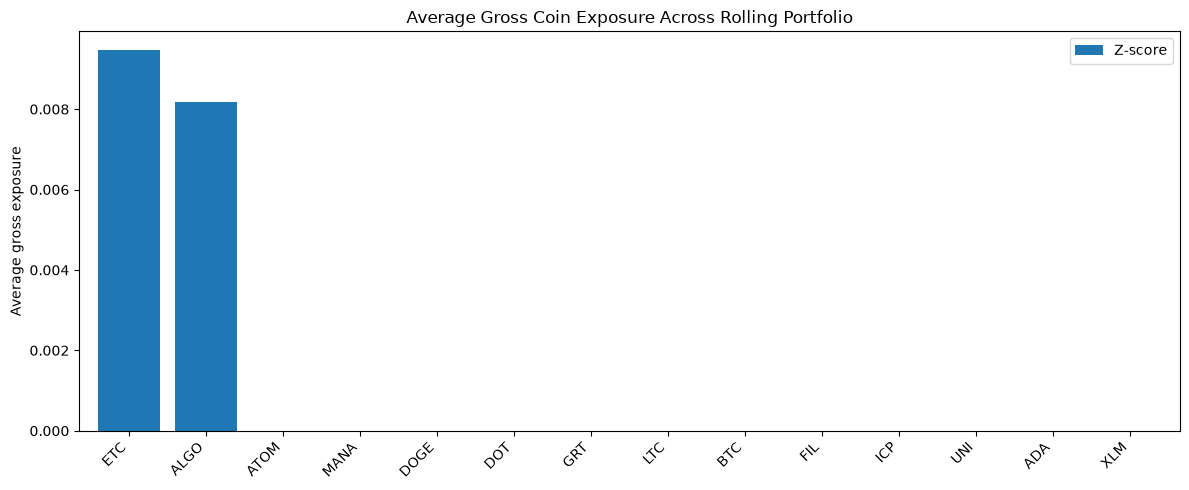

In [ ]:
z_coin_exposure  = rolling_coin_exposure(z_pair_bts, z_w_applied)

coin_exp_df = z_coin_exposure.copy()
coin_exp_df.columns = ["Z-score"]
coin_exp_df = coin_exp_df.fillna(0).sort_values("Z-score", ascending=False)

display(coin_exp_df.head(10))

ax = coin_exp_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Aggregate weighted gross coin exposure across rolling quarters")
ax.set_ylabel("Average gross exposure")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [250]:
print("Z-score quarterly weights:")
display(z_w_applied.round(4))

print("\nAverage Z-score pair weights:")
display(z_w_applied.mean().sort_values(ascending=False).to_frame("Average Weight"))

Z-score quarterly weights:


,BCH/MANA,FIL/ICP,ATOM/BCH,FIL/ETC,FIL/BCH,BTC/ADA,BCH/ICP,ICP/GRT,LINK/ALGO,DOT/ETC,...,FIL/XLM,DOGE/DOT,DOGE/GRT,XLM/ICP,DOT/LTC,DOGE/FIL,ADA/DOT,UNI/FIL,FIL/MANA,ICP/MANA
Quarter,,,,,,,,,,,,,,,,,,,,,
2025Q2,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,...,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0
2025Q3,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,...,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0
2025Q4,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,...,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0
2026Q1,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,...,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0
2026Q2,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,...,0.0000,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0
2026Q3,0.0,0.6046,0.0,0.0,0.0,0.0,0.0,0.0155,0.0,0.0,...,0.0459,0.0,0.0,0.0,0.0,0.1272,0.0,0.0,0.0,0.0



Average Z-score pair weights:


,Average Weight
ATOM/MANA,0.166667
DOGE/ATOM,0.166667
DOT/GRT,0.166667
FIL/ICP,0.100768
ALGO/ETC,0.076022
BTC/LTC,0.048079
DOGE/LTC,0.024448
ADA/LTC,0.024312
DOGE/FIL,0.021195
DOT/MANA,0.018119


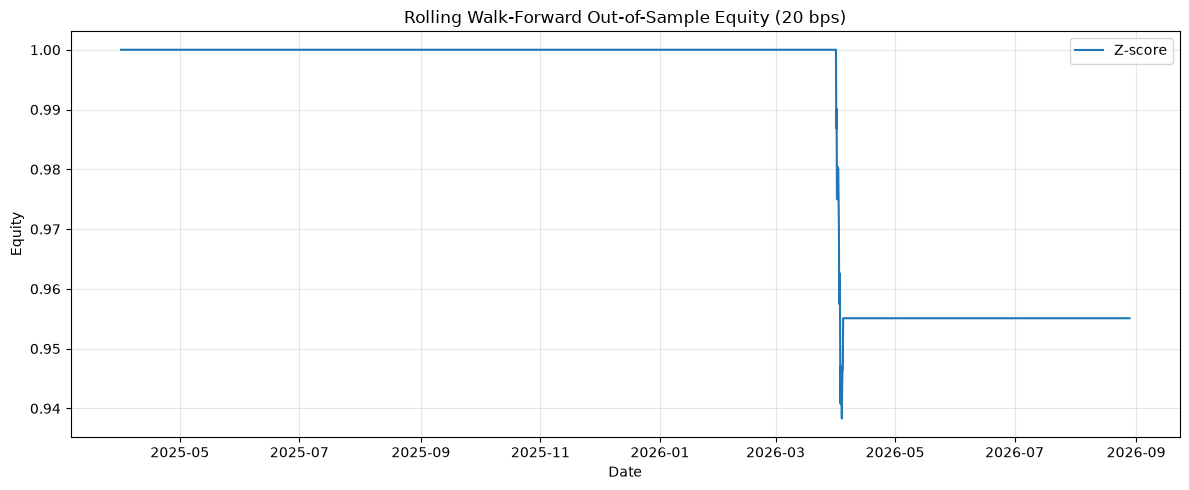

In [251]:
plt.figure(figsize=(12, 5))

plt.plot(z_port_equity,label="Z-score")

plt.title(f"Rolling Walk-Forward Out-of-Sample Equity ({FEE_BPS_MAIN:.0f} bps)")

plt.xlabel("Date")
plt.ylabel("Equity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### In-Sample vs. Out-of-Sample Performance

The notebook also compares the strategy's training-period equity curve with its final test-period equity curve.

This comparison is important because a strategy can appear attractive during development while failing when exposed to genuinely unseen data.

The training-period walk-forward parameter-selection process achieved a Sharpe ratio of approximately 0.49. Separately, an in-sample training equity curve is shown for the selected specification, while the final evaluation uses a quarterly walk-forward portfolio on unseen data.

The deterioration from positive training-period walk-forward performance to negative final out-of-sample performance is consistent with possible overfitting or instability, although this comparison alone does not establish the cause.

The results therefore reinforce the importance of evaluating the complete research process out of sample rather than reporting only the best historical parameter combination.

In [252]:
p_train_best = train_best_z.copy()

candidate_rows = []
for a, b in pairs:
    candidate_rows.append(pair_summary(p_train_best, a.split("/")[0], b.split("/")[0]))

timeframe_pairs = pd.DataFrame(candidate_rows)
timeframe_pairs = timeframe_pairs.query("Corr > 0.8")
timeframe_pairs = timeframe_pairs.query("EG_Coint_Pvalue < 0.1")
timeframe_pairs = timeframe_pairs.query("Half_life >= 12 and Half_life <= 600")
timeframe_pairs = timeframe_pairs.query("Beta_Stability <= 0.35")
timeframe_pairs = timeframe_pairs.sort_values("Z_score_Crossings", ascending=False).reset_index(drop=True)

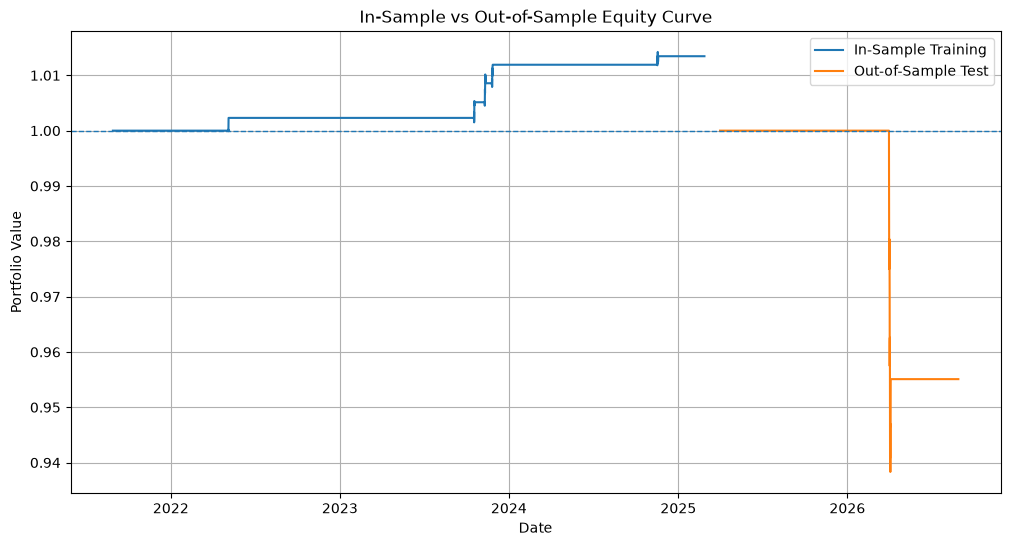

In [253]:
# ----------------------------------------------
# In-Sample vs Out-of-Sample Equity Curves
# ----------------------------------------------
# Run the winning parameter set on the training period
train_bts, train_rets, train_metrics = run_pairs(
    train_best_z,
    timeframe_pairs,
    Z_ENTRY,
    FEE_BPS_MAIN,
    window=BEST_WINDOW_Z,
    min_persist=BEST_MIN_PERSIST_BARS,
    cooldown_bars=BEST_COOLDOWN_Z,
    timeframe_hours=BEST_TIMEFRAME_Z
)

# Build an equal-volatility training portfolio
train_rets_df = pd.concat(train_rets.values(), axis=1, join="inner").dropna(how="any")
train_inv_vol = 1 / train_rets_df.std().replace(0, np.nan)
train_weights = train_inv_vol / train_inv_vol.sum()
train_port_ret = train_rets_df.mul(train_weights, axis=1).sum(axis=1)

# Training equity curve
train_equity = (1 + train_port_ret).cumprod()

# Out-of-sample equity curve from the quarterly walk-forward
test_equity = z_port_equity.copy()

# Normalize both curves to start at 1
train_equity = train_equity / train_equity.iloc[0]
test_equity = test_equity / test_equity.iloc[0]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(train_equity.index, train_equity.values, label="In-Sample Training")
plt.plot(test_equity.index, test_equity.values, label="Out-of-Sample Test")
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.title("In-Sample vs Out-of-Sample Equity Curve")
plt.legend()
plt.grid(True)
plt.show()

## BTC Comparison

### Comparison with BTC Buy-and-Hold

To contextualize the strategy's performance, the test-period portfolio is compared with a buy-and-hold BTC benchmark from April 1, 2025 through August 28, 2026.

Over the common comparison period shown in the equity-curve analysis:
Z-score strategy: approximately -4.49%
BTC buy-and-hold: approximately -6.08%

The strategy therefore lost less than BTC over that particular common interval.

However, outperforming a declining benchmark does not by itself establish a positive trading edge. The appropriate conclusion is more limited: the strategy exhibited substantially lower directional exposure to BTC and experienced a much smaller drawdown than holding BTC over the same comparison interval.

In [254]:
def hourly_to_daily(hourly_ret):
    equity = (1 + hourly_ret.fillna(0)).cumprod()
    daily_equity = equity.resample("1D").last().dropna()
    daily_ret = daily_equity.pct_change().dropna()
    return daily_ret

In [255]:
def daily_portfolio_metrics(daily_ret):
    daily_ret = daily_ret.dropna()
    equity = (1 + daily_ret.fillna(0)).cumprod()
    vol = daily_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (daily_ret.mean() / vol) * np.sqrt(252)
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (daily)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret),
    }

In [256]:
def benchmark_stats(port_daily_ret, btc_daily_ret):
    aligned = pd.concat(
        [port_daily_ret.rename("port"), btc_daily_ret.rename("btc")], axis=1
    ).dropna()
    X = sm.add_constant(aligned["btc"])
    model = sm.OLS(aligned["port"], X).fit()
    return {
        "Corr_to_BTC": aligned["port"].corr(aligned["btc"]),
        "Beta_to_BTC": model.params["btc"],
        "Alpha_Annualized": model.params["const"] * 252,
        "Alpha_tstat": model.tvalues["const"],
    }

In [257]:
btc_test_prices = test_prices.set_index("timestamp")["BTC"]
btc_daily_ret = btc_test_prices.resample("1D").last().dropna().pct_change().dropna()

z_daily_ret = hourly_to_daily(z_port_ret)

final_rows = {}
for name, daily_ret in [("Z-score", z_daily_ret)]:
    row = daily_portfolio_metrics(daily_ret)
    row.update(benchmark_stats(daily_ret, btc_daily_ret))
    final_rows[name] = row

final_summary = pd.DataFrame(final_rows).T
print(f"Final out-of-sample summary at {FEE_BPS_MAIN:.0f} bps, daily-aggregated:")
final_summary

Final out-of-sample summary at 20 bps, daily-aggregated:


/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_9121/949465896.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned = pd.concat(


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-0.772917,-0.044914,-0.061688,514.0,0.02176,0.001764,-0.022149,-1.104666


### Market Exposure

The daily regression against BTC provides additional evidence about the type of risk being taken.

The test-period results are approximately:
Correlation to BTC = 0.022
Beta to BTC = 0.002

This indicates that the strategy had very little linear exposure to BTC returns during the test period.

The estimated annualized regression alpha was approximately -2.21%, with a t-statistic of approximately -1.10.
The alpha estimate is therefore not statistically distinguishable from zero at conventional significance levels.
This reinforces the interpretation that the strategy behaved largely as a relative-value strategy rather than as a disguised long-BTC strategy.

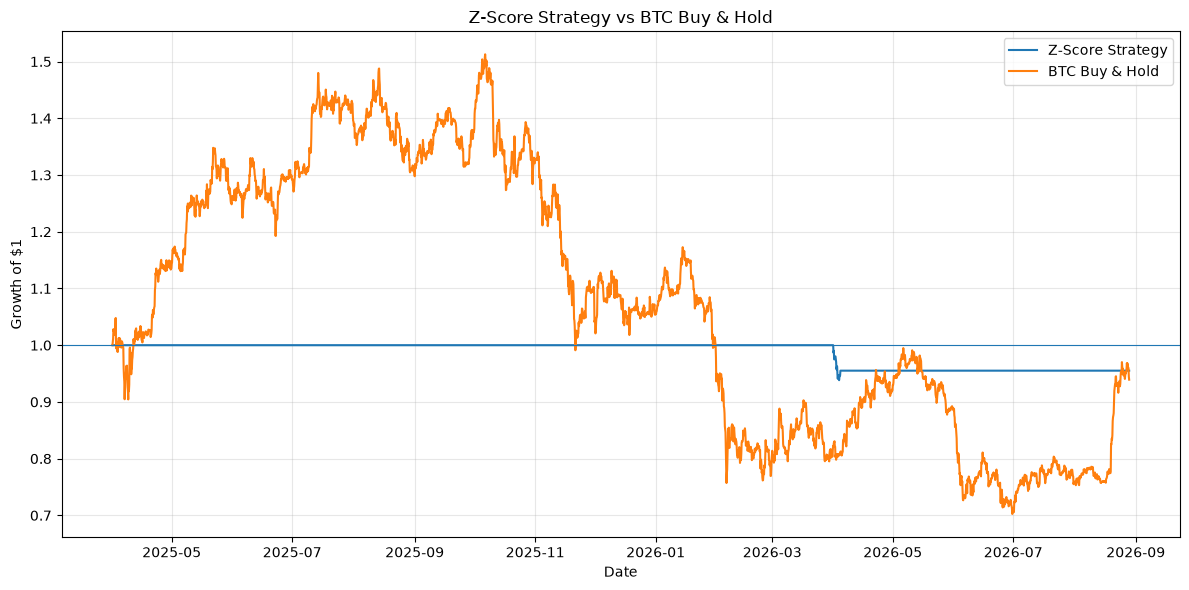

Strategy final value: $0.96
BTC final value:      $0.94
Strategy return:      -4.49%
BTC return:           -6.08%


In [258]:
# ----------------------------------------------
# Compare strategy vs BTC buy-and-hold
# ----------------------------------------------

# Strategy cumulative equity
strategy_equity = (1 + z_port_ret.fillna(0)).cumprod()

# BTC returns over the same test period
btc_prices = prices_best_z[["timestamp", "BTC"]].copy()
btc_prices = btc_prices[btc_prices["timestamp"] >= first_z_date].set_index("timestamp")
btc_returns = btc_prices["BTC"].pct_change().fillna(0)

# BTC cumulative equity
btc_equity = (1 + btc_returns).cumprod()

# Align both series to the same timestamps
comparison = pd.concat(
    [strategy_equity.rename("Strategy"), btc_equity.rename("BTC")],
    axis=1
).dropna()

# Normalize both to $1
comparison = comparison / comparison.iloc[0]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(comparison.index, comparison["Strategy"], label="Z-Score Strategy")
plt.plot(comparison.index, comparison["BTC"], label="BTC Buy & Hold")
plt.axhline(1.0, linewidth=0.8)
plt.title("Z-Score Strategy vs BTC Buy & Hold")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final outcomes
print(f"Strategy final value: ${comparison['Strategy'].iloc[-1]:.2f}")
print(f"BTC final value:      ${comparison['BTC'].iloc[-1]:.2f}")
print(f"Strategy return:      {(comparison['Strategy'].iloc[-1] - 1) * 100:.2f}%")
print(f"BTC return:           {(comparison['BTC'].iloc[-1] - 1) * 100:.2f}%")

In [259]:
strategy_row = daily_portfolio_metrics(daily_ret)
strategy_row.update(benchmark_stats(daily_ret, btc_daily_ret))

btc_row = daily_portfolio_metrics(btc_daily_ret)

# Fill columns that only make sense for the strategy
btc_row.update({
    "Corr_to_BTC": 1.0,
    "Beta_to_BTC": 1.0,
    "Alpha_Annualized": np.nan})

comparison = pd.DataFrame({
    "Z-score": strategy_row,
    "BTC Buy & Hold": btc_row
}).T

display(comparison.round(4))

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_9121/949465896.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned = pd.concat(


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-0.7729,-0.0449,-0.0617,514.0,0.0218,0.0018,-0.0221,-1.1047
BTC Buy & Hold,0.0869,-0.0738,-0.5308,548.0,1.0000,1.0000,NaN,NaN


## Interpretation
### What the Results Tell Us

The research provides evidence that a systematic framework for identifying potentially mean-reverting crypto pairs can be constructed using cointegration tests, hedge-ratio estimation, spread normalization, and walk-forward selection.

However, the final out-of-sample results do not provide evidence of a profitable strategy under the current specification.

The most important empirical observation is the gap between training-period performance and test-period performance:
Training WF Sharpe ~ approx 0.49
vs
Test Sharpe ~ approx -0.77

This performance deterioration suggests that at least one of the following may be occurring:
- historical pair relationships are not sufficiently persistent;
- the selected signal parameters are overfit to the training regime;
- the mean-reversion effect is too weak to overcome volatility and noise;
- crypto market structure changed between the training and test periods;
- the simple spread specification does not adequately capture the dynamics of the underlying assets.

These are hypotheses for further research rather than conclusions established by this backtest alone.

Additionally, across the tested fee assumptions, the Sharpe ratio remained negative and changed only modestly as transaction costs increased. This indicates that the strategy's weak risk-adjusted performance was not primarily driven by transaction costs; even under lower-fee assumptions, the strategy did not produce a positive Sharpe ratio.

### Limitations

Several limitations should be considered before interpreting the results as evidence of a tradable strategy.

1. The universe is restricted to assets with available Coinbase USD markets, so the results may not generalize to other exchanges or to the broader crypto market.

2. Transaction costs are represented by a fixed basis-point assumption. The model does not explicitly simulate bid-ask spreads, market impact, slippage, funding costs, borrow constraints, or exchange-specific execution effects.

3. The hedge ratio is estimated using a linear log-price relationship. More flexible models may capture changing relationships between cryptocurrencies more effectively.

4. The pair-selection procedure is based on statistical characteristics estimated from historical windows. Cointegration and correlation relationships can break down abruptly, particularly during major market regime changes.

5. The strategy has been evaluated over one final out-of-sample period. Additional independent test periods or cross-validation across market regimes would provide stronger evidence of robustness.

6. Portfolio-level rebalancing costs are not explicitly modeled. 

7. Transaction costs are charged on changes in the underlying pair positions, but not separately on quarterly changes in the portfolio weights assigned across pairs.

## Conclusion
This study implements and evaluates a systematic cryptocurrency pairs mean-reversion strategy.

The research pipeline consists of:
Market Universe
Pair Screening
Hedge-Ratio Estimation
Spread Construction
Z-Score Signal
Position Sizing
Walk-Forward Portfolio
Out of Sample Evaluation


The framework successfully enforces a separation between model development and final evaluation and incorporates transaction costs, turnover controls, dynamic pair selection, and exposure analysis.

Nevertheless, the final out-of-sample results are negative. The strategy generated a cumulative return of approximately -4.49%, a daily annualized Sharpe ratio of approximately -0.77, and a maximum drawdown of approximately -6.17% over the test period.

The appropriate research conclusion is therefore that the current specification does not demonstrate a statistically compelling or economically attractive mean-reversion edge in the tested crypto universe over the out-of-sample period.

This negative result is itself informative: the backtest identifies substantial room for further investigation into signal construction, regime dependence, pair stability, execution modeling, and alternative portfolio construction methods.